# BusLight - Applied Computer Vision

**FIAP · Engenharia de Software · Global Solution 2026.2 · CitizenTech**

Aline Fernandes Zeppelini (RM97966) · Camilly Breitbach Ishida (RM551474) · Julia Leite Galvão (RM550201)

Detecção de objetos em tempo real para pontos de ônibus. Em imagens e vídeos, o sistema encontra **pessoas**, **ônibus**, **cadeiras de rodas** e **andadores**, conta quantos aparecem em cada momento, estima a lotação do ponto e avisa quando há um passageiro que precisa de acessibilidade.

| Parte | Modelo | Por quê |
|---|---|---|
| Pessoas e ônibus | YOLO11s pré-treinado no COCO + ByteTrack | o COCO tem centenas de milhares de pessoas e ônibus anotados, em todo tipo de pose e movimento |
| Cadeira de rodas e andador | YOLO11s com **treinamento customizado** (transfer learning) no dataset BusLight do Roboflow | o COCO não tem essas classes |

**Privacidade (LGPD):** não há reconhecimento facial, nenhuma imagem é guardada além das saídas de teste, e a região da cabeça de cada pessoa é borrada nas imagens e vídeos gerados.

**Como rodar:** Ambiente de execução → T4 GPU, cadastrar `ROBOFLOW_API_KEY` em Secrets (🔑), e Executar tudo. Na primeira vez o treino leva cerca de 2h; o modelo fica salvo no Google Drive e, nas próximas vezes, o treino é pulado.

In [1]:
!pip install -q ultralytics roboflow lap

In [2]:
import os, glob, shutil, random, json, time, csv, urllib.request
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import torch
import yaml
import ultralytics
from ultralytics import YOLO
from IPython.display import display, Image
from PIL import Image as PILImage
from google.colab import drive, files, userdata

print("Ultralytics:", ultralytics.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NÃO ENCONTRADA (Ambiente de execução > Alterar tipo > T4 GPU)")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.215
GPU: Tesla T4


## Configuração

O Google Drive guarda o treino. Se a sessão do Colab cair no meio, é só rodar de novo que ele continua da última época salva.

In [5]:
drive.mount("/content/drive")

PASTA_DRIVE = "/content/drive/MyDrive/BusLight"
DRIVE_MODELO = f"{PASTA_DRIVE}/best_acessibilidade.pt"
SAIDAS = "/content/BusLight"
os.makedirs(PASTA_DRIVE, exist_ok=True)
os.makedirs(SAIDAS, exist_ok=True)

TREINAR = not os.path.exists(DRIVE_MODELO)  # só treina se ainda não existir modelo salvo
BORRAR_PESSOAS = True                       # LGPD: borra a cabeça das pessoas nas saídas
LOTACAO = {"baixa": 3, "media": 8}          # até 3 pessoas = baixa, até 8 = média, acima = alta

print("Vai treinar:", TREINAR)

Mounted at /content/drive
Vai treinar: True


## 1. Dataset

O dataset foi montado no Roboflow juntando conjuntos públicos do Roboflow Universe com imagens de ônibus, pessoas, cadeiras de rodas e andadores, já anotadas com caixas (bounding boxes) e exportadas no formato YOLO, divididas em treino, validação e teste.

In [6]:
from roboflow import Roboflow

rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
dataset = rf.workspace("gs-ykiiq").project("buslight-ca7ef").version(3).download("yolov8")
DATASET_DIR = dataset.location
print("Dataset em:", DATASET_DIR)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to BusLight-3 in yolov8:: 100%|██████████| 16603/16603 [00:10<00:00, 1556.20it/s]


Dataset em: /content/BusLight-3


## 2. Diagnóstico do dataset

Antes de treinar, contamos quantas caixas e imagens existem de cada classe. Esse diagnóstico explica os problemas da primeira versão do modelo:

1. Só uma pequena parte das imagens de treino tem pessoa anotada. Nas outras, as pessoas que aparecem (por exemplo, nas fotos que vieram de datasets de ônibus) não estão marcadas, e o modelo aprende que pessoa é "fundo". Por isso ele perdia pessoas, principalmente em movimento.
2. `wheelchair` e `wheelchairs` são a mesma coisa em duas classes, o que divide os exemplos.
3. Há poucos exemplos de andador.

In [7]:
config = yaml.safe_load(open(os.path.join(DATASET_DIR, "data.yaml")))
NOMES = config["names"]
if isinstance(NOMES, dict):
    NOMES = [NOMES[k] for k in sorted(NOMES)]

diagnostico = []
for divisao in ["train", "valid", "test"]:
    caixas, imagens = Counter(), Counter()
    arquivos = glob.glob(f"{DATASET_DIR}/{divisao}/labels/*.txt")
    for arq in arquivos:
        classes = [int(l.split()[0]) for l in open(arq) if l.strip()]
        caixas.update(classes)
        imagens.update(set(classes))
    for c, nome in enumerate(NOMES):
        diagnostico.append({"divisão": divisao, "total de imagens": len(arquivos), "classe": nome,
                            "caixas": caixas[c], "imagens com a classe": imagens[c]})

diagnostico = pd.DataFrame(diagnostico)
diagnostico.to_csv(f"{SAIDAS}/diagnostico_dataset.csv", index=False)
diagnostico

,divisão,total de imagens,classe,caixas,imagens com a classe
0,train,5816,Bus,1835,1275
1,train,5816,Person,1672,393
2,train,5816,walking-frame,107,87
3,train,5816,wheelchair,92,92
4,train,5816,wheelchairs,4751,4033
5,valid,1656,Bus,707,417
6,valid,1656,Person,618,172
7,valid,1656,walking-frame,54,42
8,valid,1656,wheelchair,35,35
9,valid,1656,wheelchairs,1176,1018


## 3. Preparação: dataset só de acessibilidade

Para o modelo customizado ficamos só com as caixas de andador e cadeira de rodas (`wheelchair` e `wheelchairs` viram uma classe só). Imagens sem nenhuma delas entram 10% das vezes no treino e na validação, como exemplos de fundo; no teste entram todas, para a avaliação ser honesta. Isso também deixa o treino bem mais rápido.

In [8]:
NOVAS_CLASSES = ["andador", "cadeira de rodas"]
MAPA = {}
for i, nome in enumerate(NOMES):
    if "walking" in nome.lower():
        MAPA[i] = 0
    elif "wheelchair" in nome.lower():
        MAPA[i] = 1
print("Mapeamento (id antigo -> novo):", MAPA)

ACESS_DIR = "/content/acessibilidade"
shutil.rmtree(ACESS_DIR, ignore_errors=True)
random.seed(42)

for divisao in ["train", "valid", "test"]:
    os.makedirs(f"{ACESS_DIR}/{divisao}/images", exist_ok=True)
    os.makedirs(f"{ACESS_DIR}/{divisao}/labels", exist_ok=True)
    com_objeto = fundo = 0

    for arq in sorted(glob.glob(f"{DATASET_DIR}/{divisao}/labels/*.txt")):
        linhas = []
        for linha in open(arq):
            partes = linha.split()
            if partes and int(partes[0]) in MAPA:
                linhas.append(" ".join([str(MAPA[int(partes[0])])] + partes[1:]))

        if not linhas and divisao != "test" and random.random() > 0.10:
            continue

        base = os.path.splitext(os.path.basename(arq))[0]
        imagem = glob.glob(f"{DATASET_DIR}/{divisao}/images/{glob.escape(base)}.*")
        if not imagem:
            continue
        shutil.copy(imagem[0], f"{ACESS_DIR}/{divisao}/images/")
        with open(f"{ACESS_DIR}/{divisao}/labels/{base}.txt", "w") as f:
            f.write("\n".join(linhas))
        if linhas:
            com_objeto += 1
        else:
            fundo += 1

    print(f"{divisao}: {com_objeto} com cadeira/andador + {fundo} de fundo")

ACESS_YAML = f"{ACESS_DIR}/data.yaml"
yaml.safe_dump({
    "path": ACESS_DIR,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": dict(enumerate(NOVAS_CLASSES)),
}, open(ACESS_YAML, "w"), allow_unicode=True)

Mapeamento (id antigo -> novo): {2: 0, 3: 1, 4: 1}
train: 4147 com cadeira/andador + 162 de fundo
valid: 1067 com cadeira/andador + 58 de fundo
test: 495 com cadeira/andador + 332 de fundo


## 4. Treinamento customizado (cadeira de rodas e andador)

| Parâmetro | Valor | Motivo |
|---|---|---|
| Modelo base | YOLO11s (pesos do COCO) | transfer learning; um pouco maior que o 11n e bem mais preciso, ainda leve para tempo real |
| Épocas | 40, parando antes se passar 10 sem melhora | na primeira rodada o mAP estabilizou antes da época 40 |
| Imagem | 640 x 640 | padrão do YOLO |
| Batch | automático (`-1`) | usa o maior batch que cabe na T4 |
| Cache | disco | evita decodificar as imagens de novo a cada época |
| Augmentation | padrão do Ultralytics (mosaic, flip, HSV, escala) | ajuda com variação de luz, ângulo e tamanho |

In [9]:
PASTA_TREINO = f"{PASTA_DRIVE}/treino"
ULTIMO = f"{PASTA_TREINO}/acessibilidade/weights/last.pt"

if TREINAR:
    if os.path.exists(ULTIMO):
        print("Retomando o treino interrompido:", ULTIMO)
        treino = YOLO(ULTIMO).train(resume=True)
    else:
        treino = YOLO("yolo11s.pt").train(
            data=ACESS_YAML,
            epochs=40,
            patience=10,
            imgsz=640,
            batch=-1,
            cache="disk",
            workers=2,
            device=0,
            project=PASTA_TREINO,
            name="acessibilidade",
            exist_ok=True,
        )
    shutil.copy(os.path.join(str(treino.save_dir), "weights", "best.pt"), DRIVE_MODELO)
    print("Modelo salvo no Drive:", DRIVE_MODELO)
else:
    print("Já existe modelo treinado no Drive, pulando o treino:", DRIVE_MODELO)

acess = YOLO(DRIVE_MODELO)
print("Classes:", acess.names)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/acessibilidade/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=acessibilidade, nbs=64, nms=None, opset=None, optimize=F

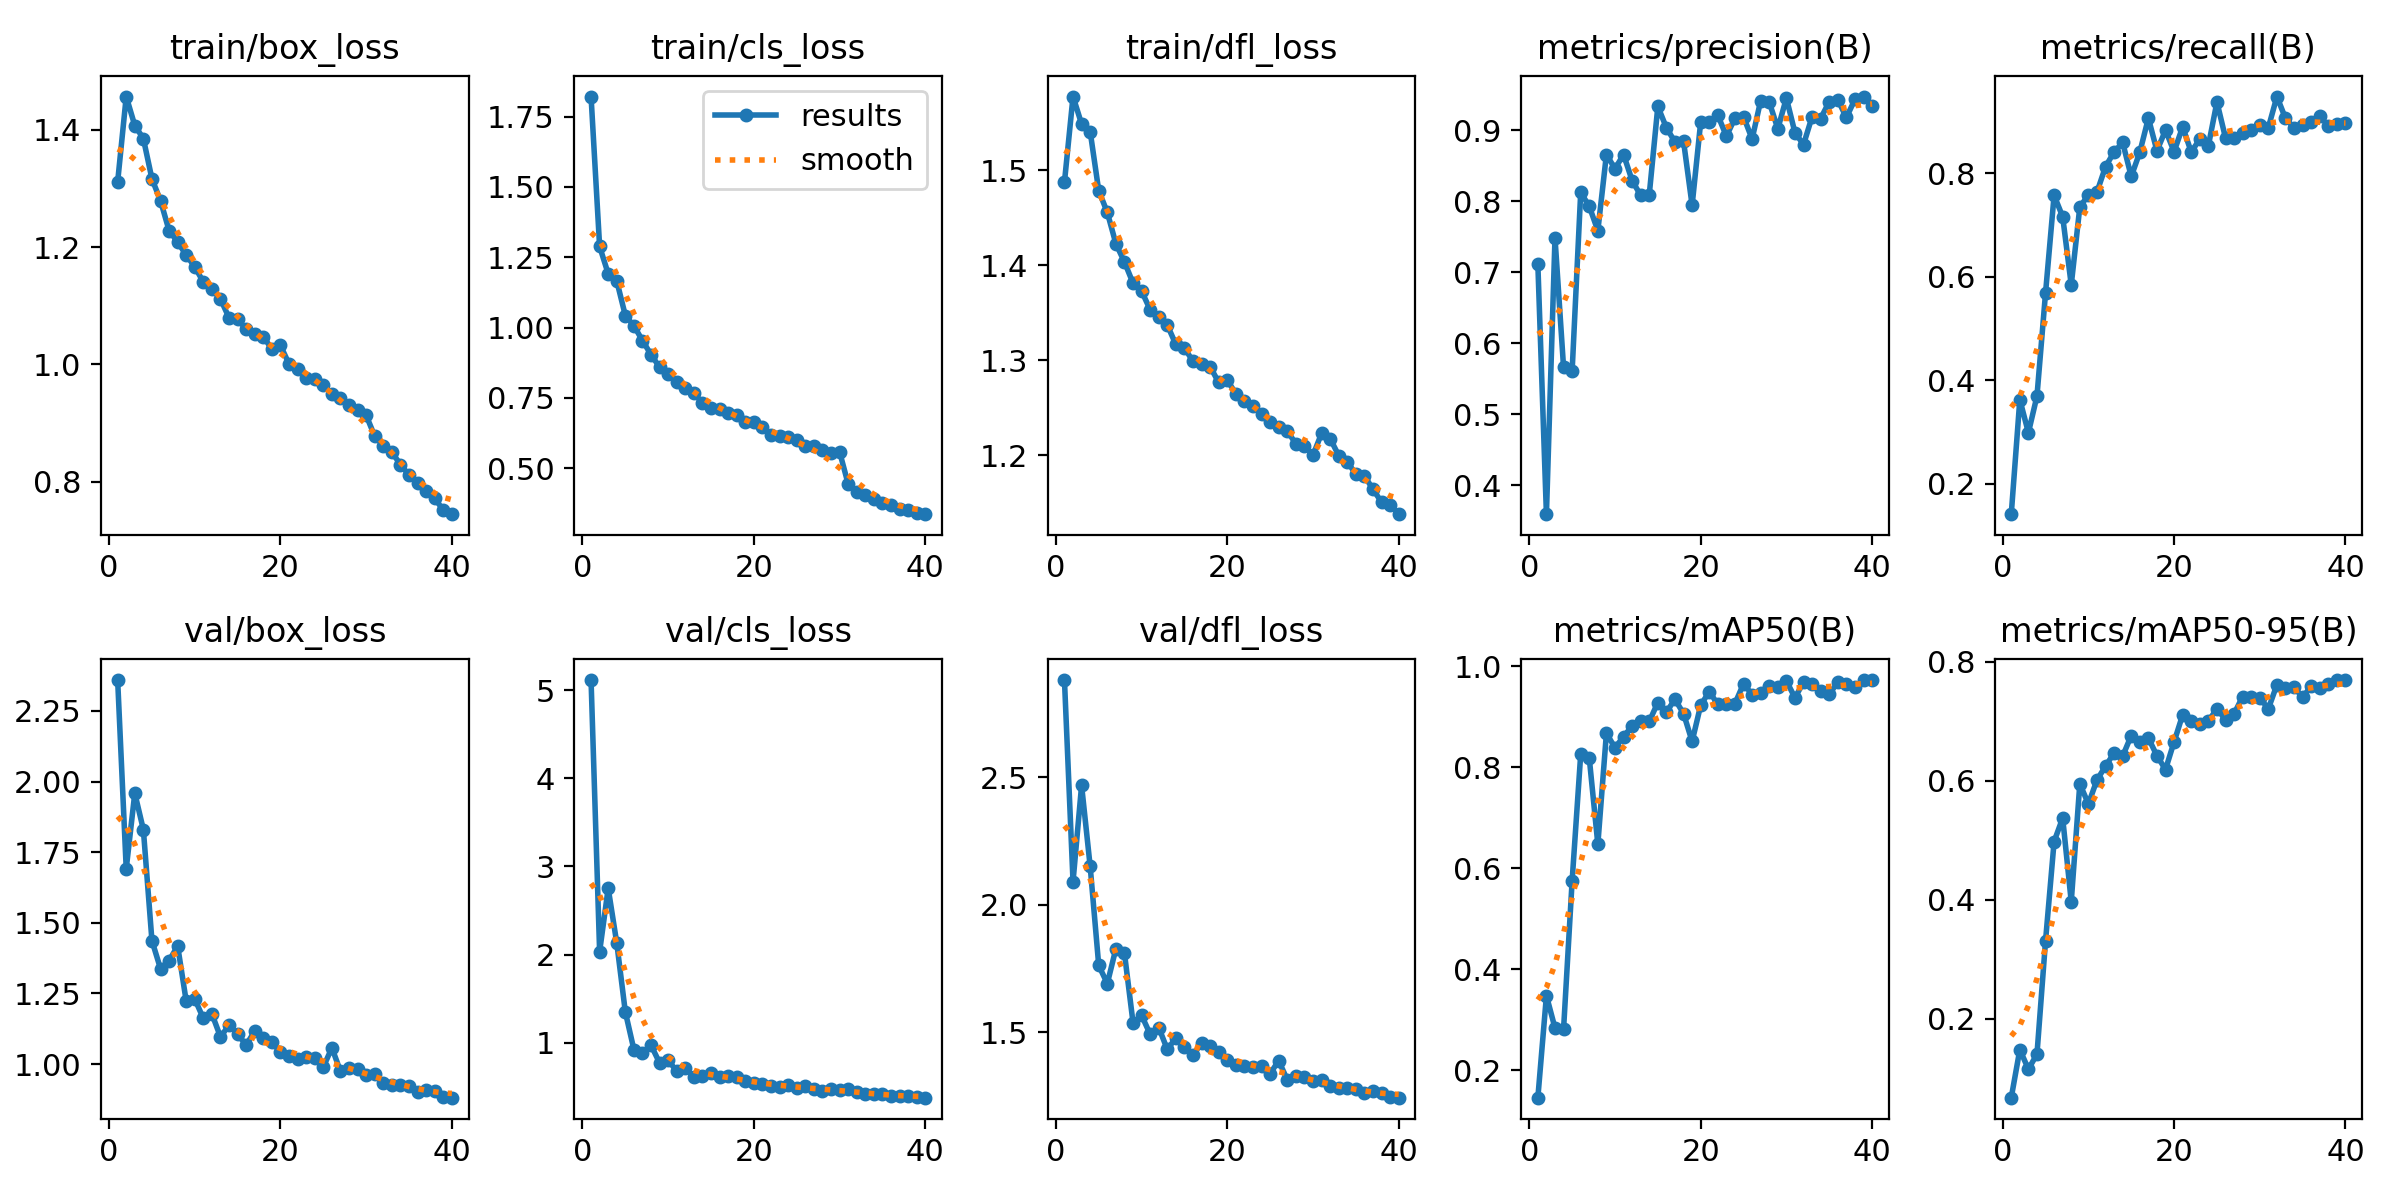

In [10]:
# curvas de perda e de mAP ao longo das épocas
curvas = f"{PASTA_TREINO}/acessibilidade/results.png"
if os.path.exists(curvas):
    shutil.copy(curvas, f"{SAIDAS}/curvas_treino.png")
    display(Image(filename=curvas, width=900))

## 5. Avaliação no conjunto de teste

- **Precisão**: das caixas que o modelo desenhou, quantas estavam certas.
- **Recall**: dos objetos que existiam, quantos o modelo achou.
- **mAP50**: média da precisão considerando acerto quando a caixa sobrepõe pelo menos 50% da caixa real.
- **mAP50-95**: a mesma coisa, mas exigindo sobreposições de 50% a 95% (mais rigoroso com a posição da caixa).

In [11]:
metricas = acess.val(data=ACESS_YAML, split="test", imgsz=640, device=0, plots=True)

resultado_teste = pd.DataFrame(
    [{"classe": "todas", "precisão": metricas.box.mp, "recall": metricas.box.mr,
      "mAP50": metricas.box.map50, "mAP50-95": metricas.box.map}] +
    [{"classe": acess.names[int(c)], "precisão": p, "recall": r, "mAP50": a50, "mAP50-95": a}
     for k, c in enumerate(metricas.box.ap_class_index)
     for p, r, a50, a in [metricas.box.class_result(k)]]
).round(3)
resultado_teste.to_csv(f"{SAIDAS}/metricas_teste.csv", index=False)
resultado_teste

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 27.9±18.4 MB/s, size: 70.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/acessibilidade/test/labels... 827 images, 332 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 827/827 904.6it/s 0.9s
val: New cache created: /content/acessibilidade/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 52/52 4.1it/s 12.7s
                   all        827        582      0.935      0.958       0.99      0.795
               andador          7          9      0.898          1      0.995      0.865
      cadeira de rodas        493        573      0.972      0.915      0.984      0.725
S

,classe,precisão,recall,mAP50,mAP50-95
0,todas,0.935,0.958,0.990,0.795
1,andador,0.898,1.000,0.995,0.865
2,cadeira de rodas,0.972,0.915,0.984,0.725


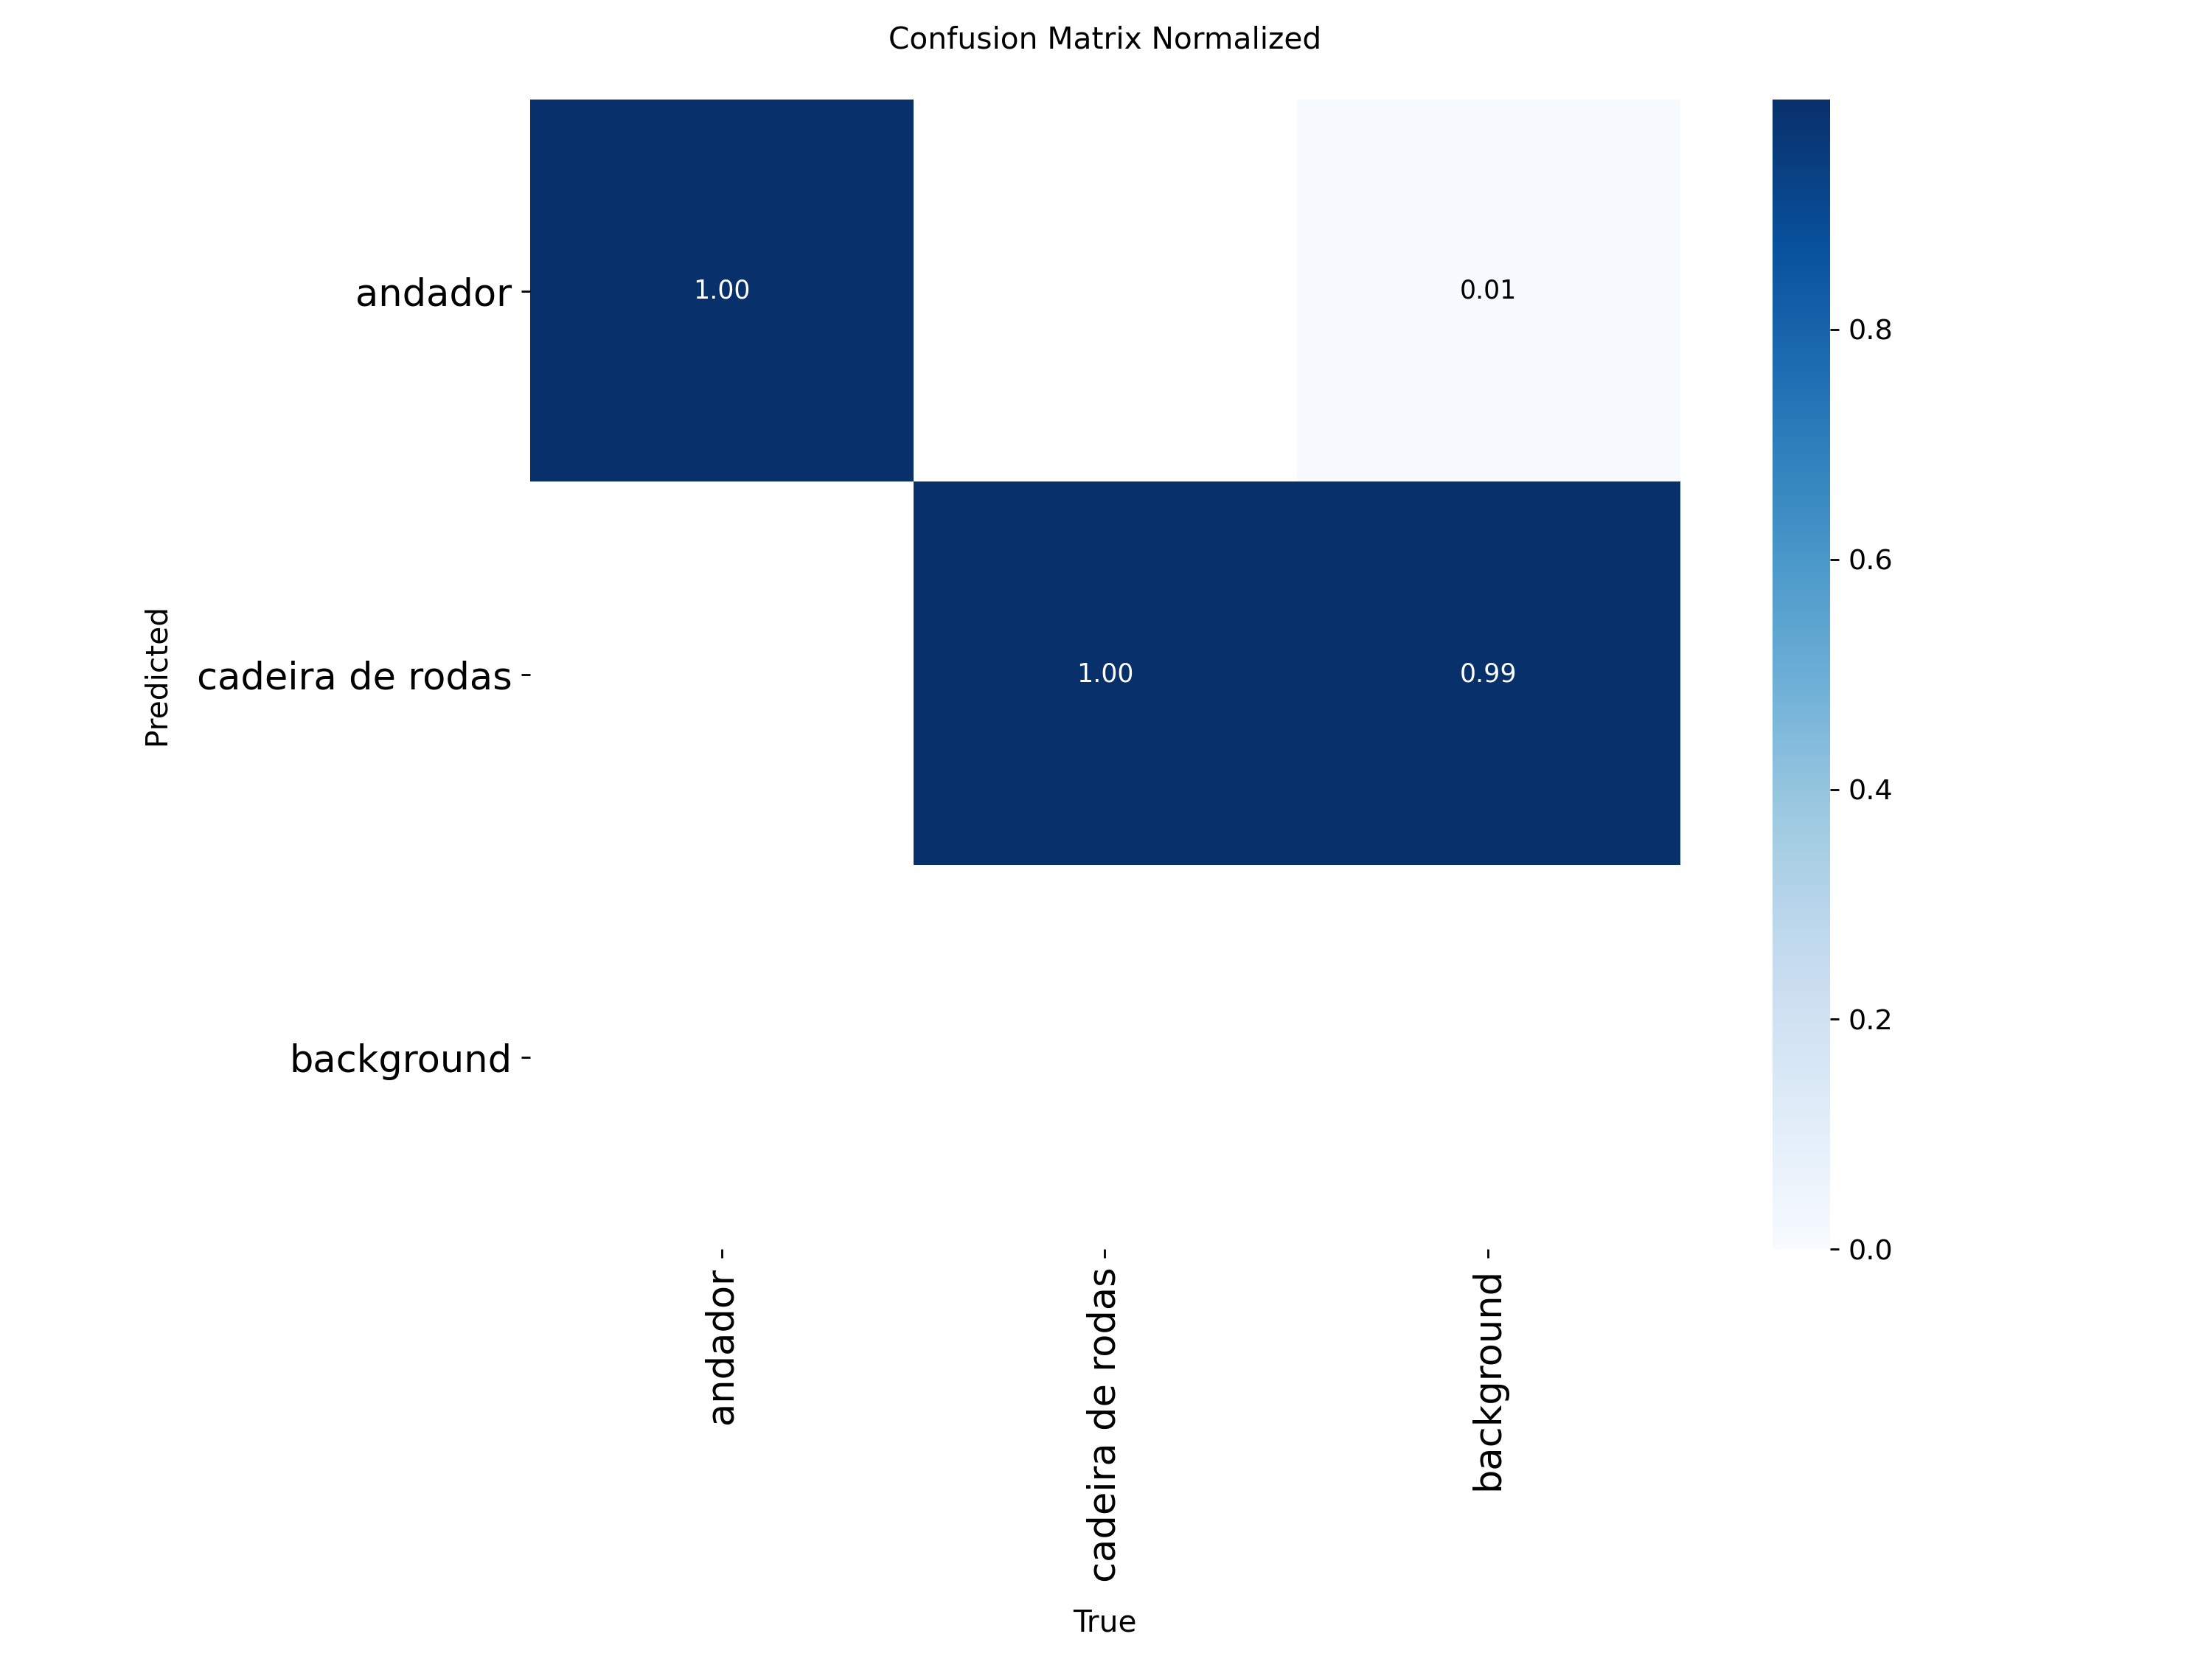

In [12]:
matriz = os.path.join(str(metricas.save_dir), "confusion_matrix_normalized.png")
shutil.copy(matriz, f"{SAIDAS}/matriz_confusao.png")
display(Image(filename=matriz, width=700))

## 6. Comparação com a versão 1

A versão 1 era um modelo único (YOLO11n) treinado nas 5 classes originais (`best(2).pt`, baixado do repositório). As duas versões são avaliadas nas **mesmas imagens de teste**.

Cuidado ao ler a linha de **pessoa**: no teste, poucas imagens têm pessoas anotadas e muitas pessoas que aparecem nas fotos não estão marcadas. Quando a versão 2 acha essas pessoas, a métrica conta como erro. Por isso, para pessoa, o **recall** (das pessoas anotadas, quantas foram achadas) é a comparação mais justa, junto com as imagens e o vídeo lado a lado mais abaixo.

In [13]:
MODELO_ANTIGO = "/content/modelo_v1.pt"
if not os.path.exists(MODELO_ANTIGO):
    urllib.request.urlretrieve("https://github.com/linesiscl/GS-BusLight-Applied-CV/raw/main/best%282%29.pt", MODELO_ANTIGO)
antigo = YOLO(MODELO_ANTIGO)
coco = YOLO("yolo11s.pt")

# teste original com os rótulos de pessoa e ônibus trocados para os ids do COCO (pessoa = 0, ônibus = 5)
COCO_DIR = "/content/teste_coco"
os.makedirs(f"{COCO_DIR}/test/labels", exist_ok=True)
if not os.path.exists(f"{COCO_DIR}/test/images"):
    os.symlink(f"{DATASET_DIR}/test/images", f"{COCO_DIR}/test/images")
PARA_COCO = {NOMES.index("Person"): 0, NOMES.index("Bus"): 5}
for arq in glob.glob(f"{DATASET_DIR}/test/labels/*.txt"):
    linhas = []
    for linha in open(arq):
        partes = linha.split()
        if partes and int(partes[0]) in PARA_COCO:
            linhas.append(" ".join([str(PARA_COCO[int(partes[0])])] + partes[1:]))
    with open(f"{COCO_DIR}/test/labels/{os.path.basename(arq)}", "w") as f:
        f.write("\n".join(linhas))
COCO_YAML = f"{COCO_DIR}/data.yaml"
yaml.safe_dump({"path": COCO_DIR, "train": "test/images", "val": "test/images", "test": "test/images",
                "names": coco.names}, open(COCO_YAML, "w"))


def por_classe(m, nomes):
    saida = {}
    for k, c in enumerate(m.box.ap_class_index):
        saida[nomes[int(c)]] = m.box.class_result(k)
    return saida


v1 = por_classe(antigo.val(data=os.path.join(DATASET_DIR, "data.yaml"), split="test", device=0, plots=False, verbose=False), antigo.names)
v2 = por_classe(coco.val(data=COCO_YAML, split="test", device=0, plots=False, verbose=False), coco.names)
v2.update(por_classe(metricas, acess.names))

pares = [
    ("Pessoa", v1.get("Person"), v2.get("person")),
    ("Ônibus", v1.get("Bus"), v2.get("bus")),
    ("Cadeira de rodas", v1.get("wheelchairs"), v2.get("cadeira de rodas")),
    ("Andador", v1.get("walking-frame"), v2.get("andador")),
]
comparacao = pd.DataFrame([
    {"classe": nome,
     "recall v1": a[1] if a else None, "recall v2": b[1] if b else None,
     "mAP50 v1": a[2] if a else None, "mAP50 v2": b[2] if b else None,
     "mAP50-95 v1": a[3] if a else None, "mAP50-95 v2": b[3] if b else None}
    for nome, a, b in pares
]).round(3)
comparacao.to_csv(f"{SAIDAS}/comparacao_v1_v2.csv", index=False)
print("Na versão 1, cadeira de rodas usa a classe 'wheelchairs', que tem quase todas as caixas do teste.")
comparacao

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 28.5±14.5 MB/s, size: 40.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/BusLight-3/test/labels... 827 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 827/827 573.3it/s 1.4s
val: New cache created: /content/BusLight-3/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 52/52 6.0it/s 8.7s
                   all        827       1163      0.841      0.826      0.878      0.678
Speed: 0.9ms preprocess, 3.0ms inference, 0.0ms loss, 1.4ms postprocess per image
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 

,classe,recall v1,recall v2,mAP50 v1,mAP50 v2,mAP50-95 v1,mAP50-95 v2
0,Pessoa,0.504,0.035,0.585,0.000,0.344,0.000
1,Ônibus,0.733,NaN,0.846,NaN,0.657,NaN
2,Cadeira de rodas,0.894,0.915,0.969,0.984,0.659,0.725
3,Andador,1.000,1.000,0.995,0.995,0.837,0.865


## 7. Detector do BusLight

Junta os dois modelos em uma função só:

1. `coco` encontra pessoas e ônibus; no vídeo, o **ByteTrack** dá um ID para cada pessoa e acompanha ela entre os frames. Ajustamos o ByteTrack para segurar o ID por 60 frames quando a pessoa some por um instante (desfoque, alguém passando na frente).
2. `acess` (nosso modelo) encontra cadeira de rodas e andador.
3. A contagem vira informação para o ponto: **lotação** (baixa, média, alta) e **alerta de acessibilidade** quando há cadeira de rodas ou andador.

In [14]:
tracker = yaml.safe_load(open(os.path.join(os.path.dirname(ultralytics.__file__), "cfg/trackers/bytetrack.yaml")))
tracker["track_buffer"] = 60
tracker["track_low_thresh"] = 0.1
TRACKER = "/content/bytetrack_buslight.yaml"
yaml.safe_dump(tracker, open(TRACKER, "w"))

PESSOA, ONIBUS = 0, 5


def lotacao(pessoas):
    if pessoas <= LOTACAO["baixa"]:
        return "baixa"
    if pessoas <= LOTACAO["media"]:
        return "media"
    return "alta"


def borrar_pessoas(frame, r_coco):
    for (x1, y1, x2, y2), c in zip(r_coco.boxes.xyxy.int().tolist(), r_coco.boxes.cls.int().tolist()):
        if c != PESSOA:
            continue
        x1, y1 = max(0, x1), max(0, y1)
        y_cabeca = y1 + max(1, (y2 - y1) // 4)
        regiao = frame[y1:y_cabeca, x1:x2]
        if regiao.size:
            frame[y1:y_cabeca, x1:x2] = cv2.GaussianBlur(regiao, (51, 51), 0)


def detectar(frame, rastrear=False):
    if rastrear:
        r_coco = coco.track(frame, persist=True, tracker=TRACKER, classes=[PESSOA, ONIBUS],
                            conf=0.30, verbose=False)[0]
    else:
        r_coco = coco.predict(frame, classes=[PESSOA, ONIBUS], conf=0.30, verbose=False)[0]
    r_acess = acess.predict(frame, conf=0.40, verbose=False)[0]

    cls_coco = r_coco.boxes.cls.int().tolist()
    cls_acess = r_acess.boxes.cls.int().tolist()
    contagem = {
        "pessoas": cls_coco.count(PESSOA),
        "onibus": cls_coco.count(ONIBUS),
        "andador": cls_acess.count(0),
        "cadeira de rodas": cls_acess.count(1),
    }
    contagem["lotacao"] = lotacao(contagem["pessoas"])

    base = frame.copy()
    if BORRAR_PESSOAS:
        borrar_pessoas(base, r_coco)
    imagem = r_acess.plot(img=r_coco.plot(img=base))

    texto = (f"Pessoas: {contagem['pessoas']}  Lotacao: {contagem['lotacao']}  Onibus: {contagem['onibus']}  "
             f"Cadeira: {contagem['cadeira de rodas']}  Andador: {contagem['andador']}")
    cv2.rectangle(imagem, (0, 0), (imagem.shape[1], 40), (0, 0, 0), -1)
    cv2.putText(imagem, texto, (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
    if contagem["cadeira de rodas"] or contagem["andador"]:
        cv2.rectangle(imagem, (0, 40), (imagem.shape[1], 80), (0, 0, 200), -1)
        cv2.putText(imagem, "ACESSIBILIDADE: passageiro precisa de apoio no embarque", (10, 68),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
    return imagem, contagem, r_coco

## 8. Exemplos de resultados

### 8.1 Imagens do conjunto de teste

Seis imagens de teste que o modelo nunca viu no treino, com as detecções dos dois modelos.

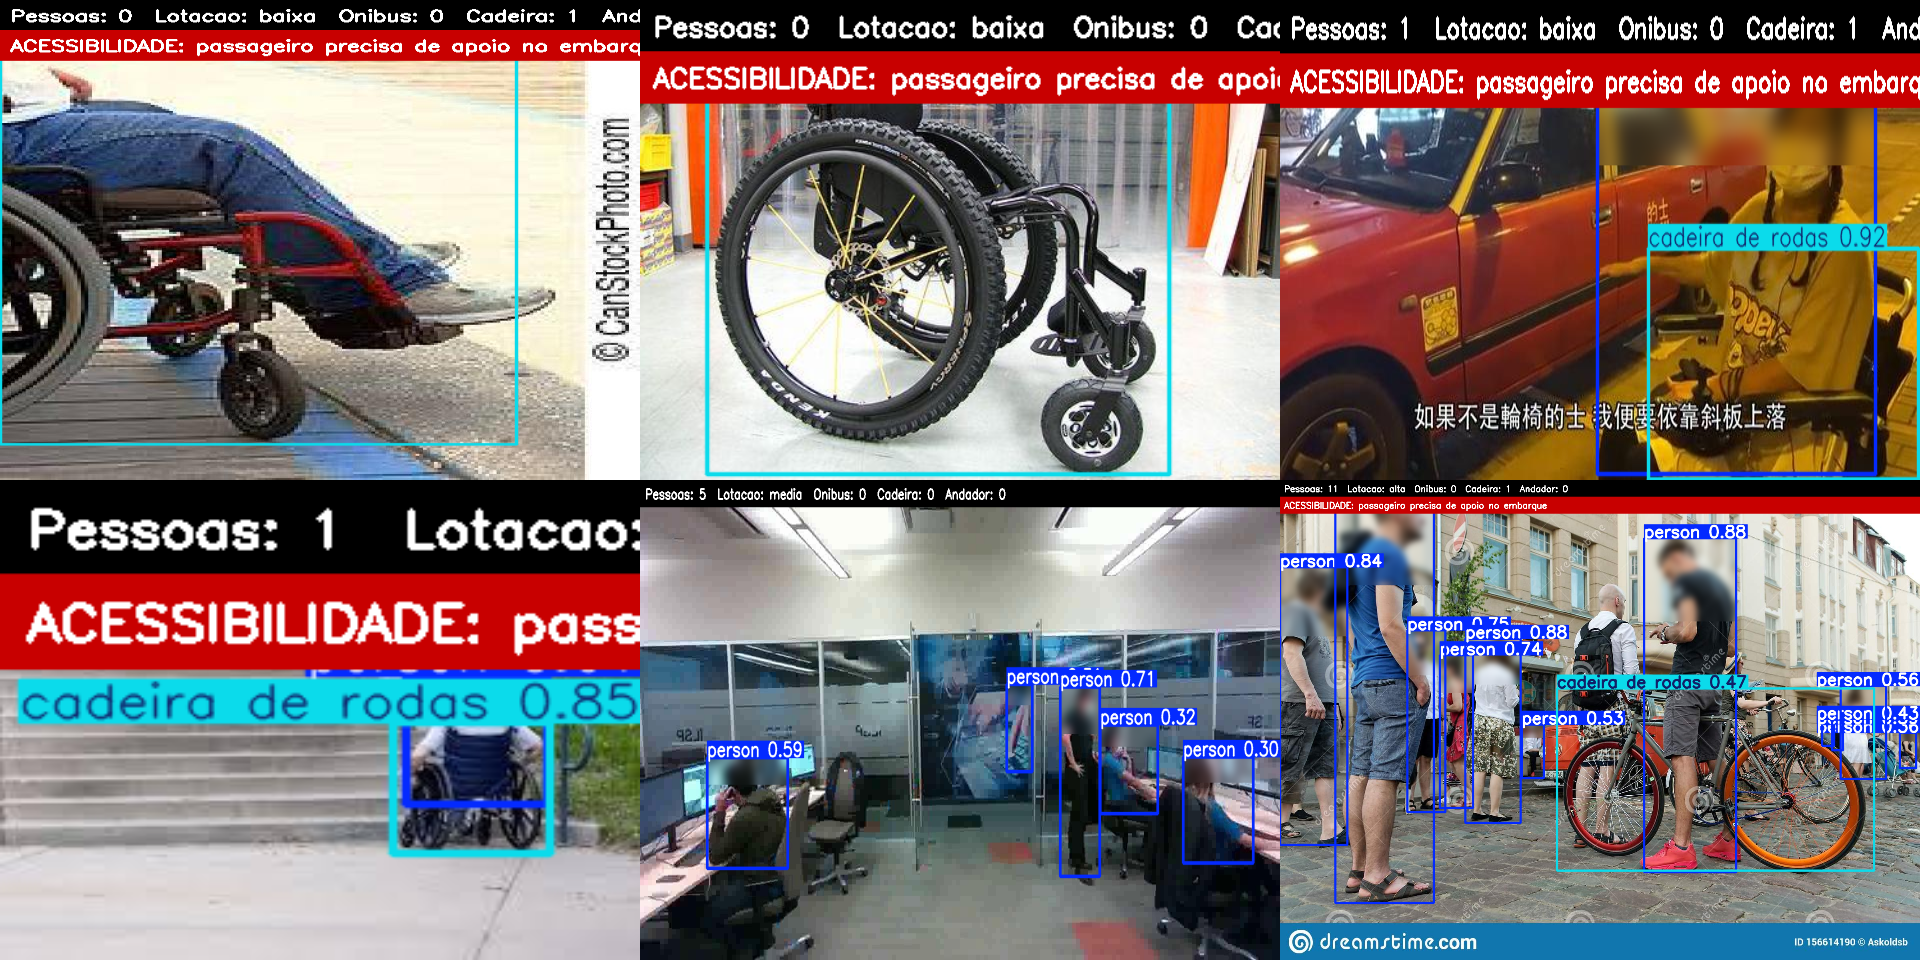

In [15]:
random.seed(7)
com_cadeira = [p for p in glob.glob(f"{ACESS_DIR}/test/labels/*.txt") if open(p).read().strip()]
com_pessoa = [p for p in glob.glob(f"{COCO_DIR}/test/labels/*.txt") if any(l.startswith("0 ") for l in open(p))]
escolhidas = random.sample(com_cadeira, min(4, len(com_cadeira))) + random.sample(com_pessoa, min(2, len(com_pessoa)))

quadros = []
for rotulo in escolhidas:
    base = os.path.splitext(os.path.basename(rotulo))[0]
    caminho = glob.glob(f"{DATASET_DIR}/test/images/{glob.escape(base)}.*")[0]
    imagem, _, _ = detectar(cv2.imread(caminho))
    quadros.append(cv2.resize(imagem, (640, 480)))
while len(quadros) < 6:
    quadros.append(np.zeros((480, 640, 3), dtype=np.uint8))

grade = np.vstack([np.hstack(quadros[0:3]), np.hstack(quadros[3:6])])
cv2.imwrite(f"{SAIDAS}/exemplos_teste.jpg", grade)
display(PILImage.fromarray(grade[..., ::-1]))

### 8.2 Sua imagem: versão 1 x versão 2

Envie uma foto de ponto de ônibus. À esquerda, a versão 1; à direita, a versão 2.

Saving Asqd_R2_2R5JEDn9tKIyViNdYamq_5hzfr-JtTdoeQzVmKk7RIH1HMiAsugCZyrK7vESwp588R9gZTpSgDCFjp1l4pjj-rrEOlsRWcqUrWnQOEW4TrXbvL3U8Gkp4fz_nyVeCj1hOOkimTGMGO6mH3P1b0GryWHT6O_y9ih2N2G3G8wVkmvYYLb8cuqmqg8y.jpg to Asqd_R2_2R5JEDn9tKIyViNdYamq_5hzfr-JtTdoeQzVmKk7RIH1HMiAsugCZyrK7vESwp588R9gZTpSgDCFjp1l4pjj-rrEOlsRWcqUrWnQOEW4TrXbvL3U8Gkp4fz_nyVeCj1hOOkimTGMGO6mH3P1b0GryWHT6O_y9ih2N2G3G8wVkmvYYLb8cuqmqg8y.jpg


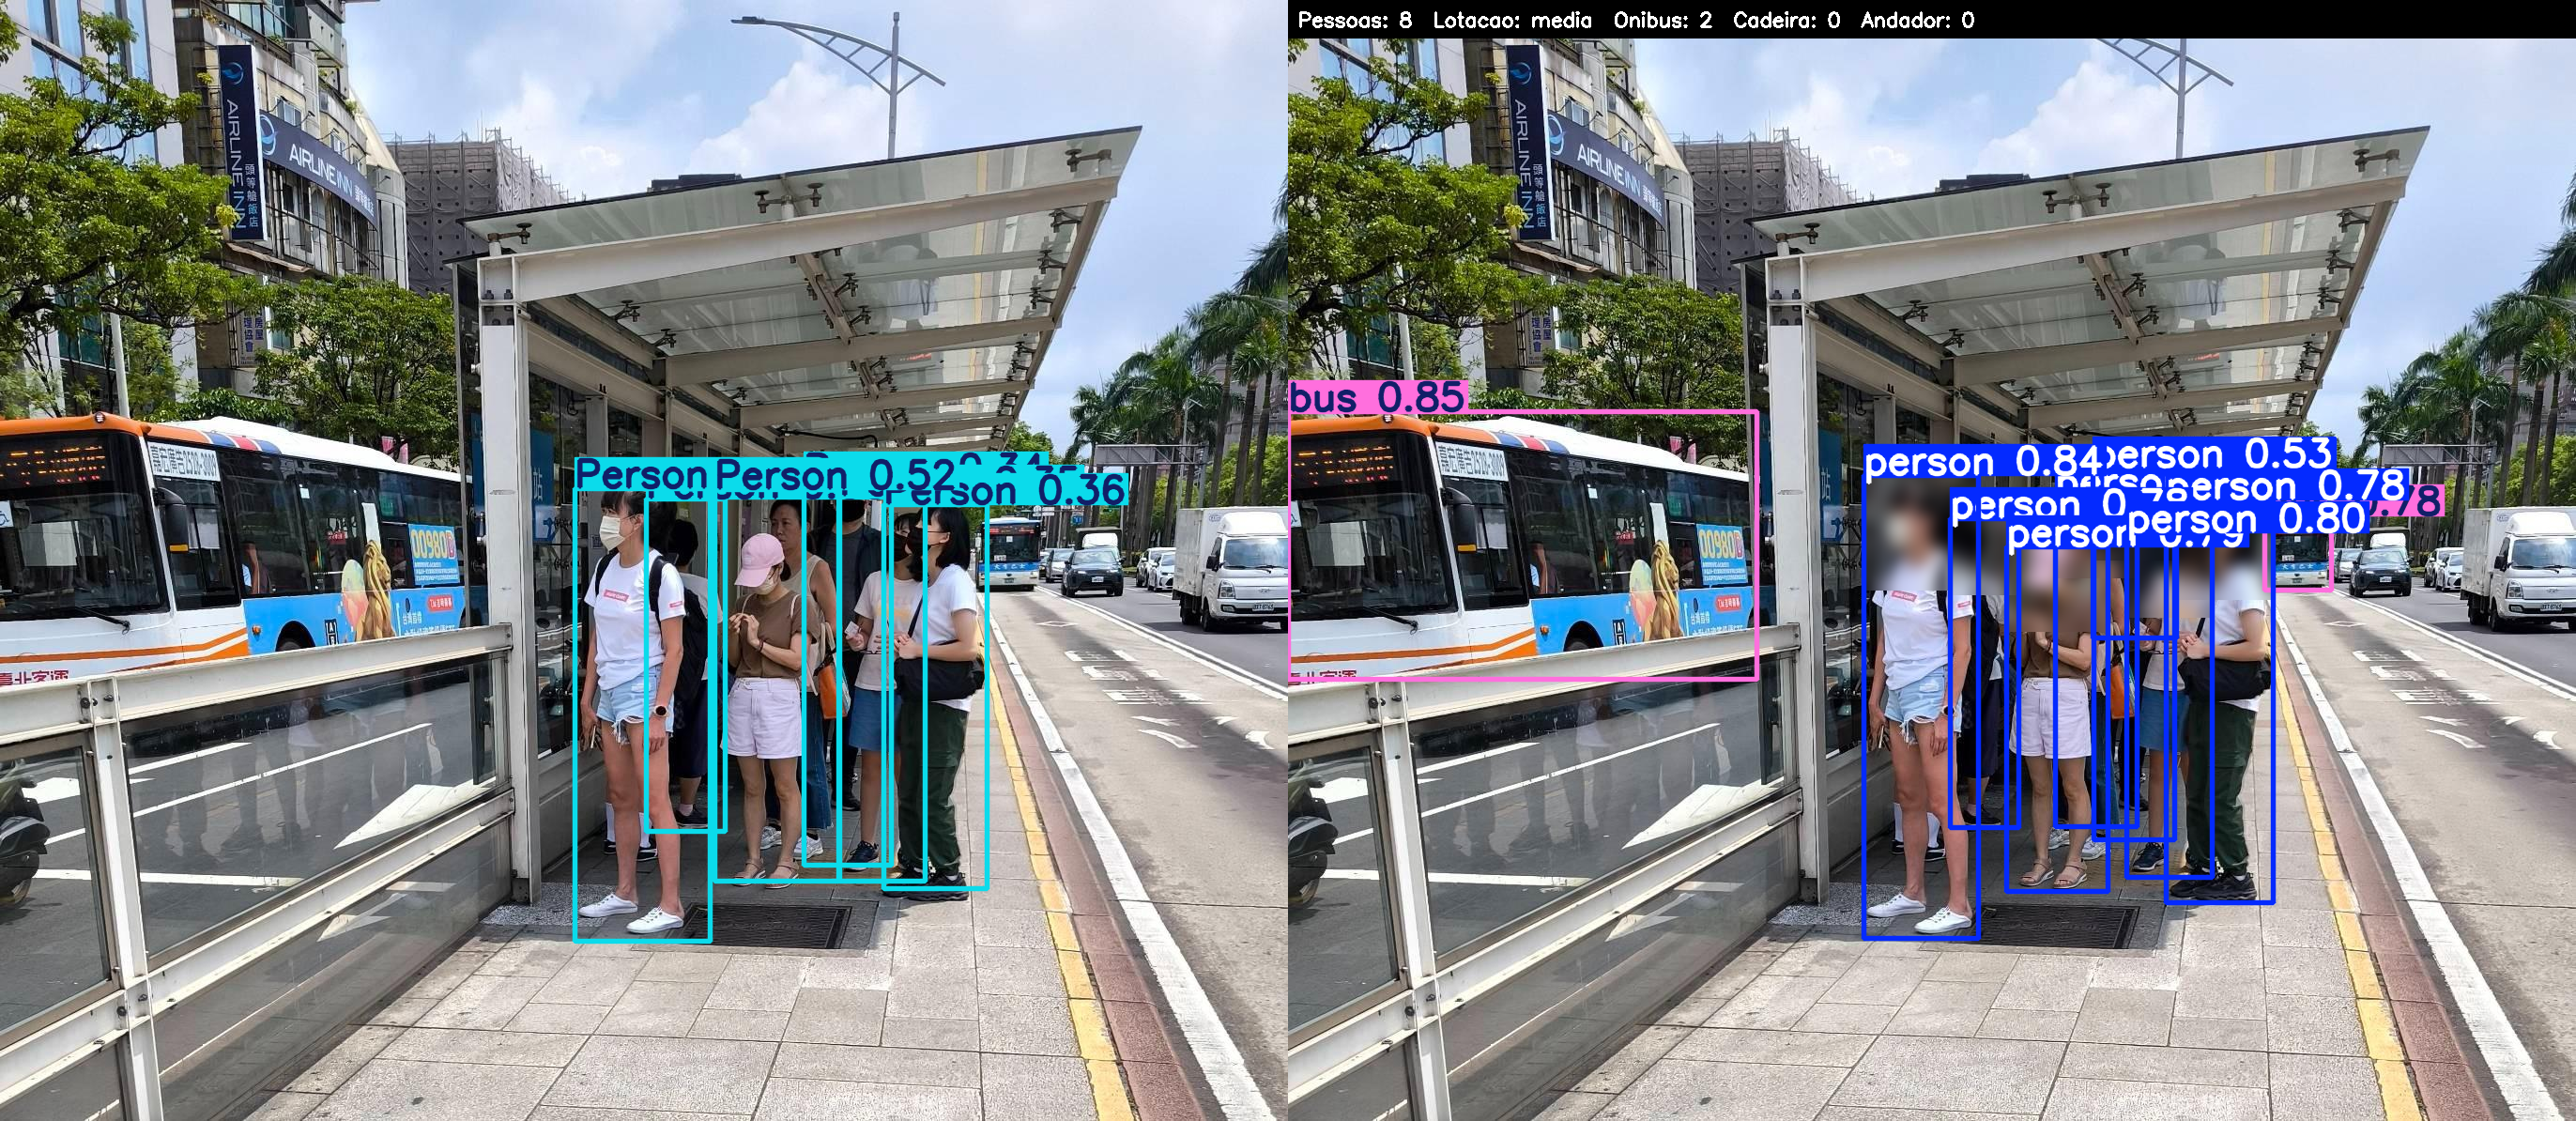

Versão 1: {'Person': 6}
Versão 2: {'pessoas': 8, 'onibus': 2, 'andador': 0, 'cadeira de rodas': 0, 'lotacao': 'media'}


In [17]:
enviado = files.upload()
IMAGEM = next(iter(enviado))
frame = cv2.imread(IMAGEM)

r_antigo = antigo.predict(frame, conf=0.25, verbose=False)[0]
cont_antigo = Counter(r_antigo.names[c] for c in r_antigo.boxes.cls.int().tolist())
novo, contagem, _ = detectar(frame)

lado_a_lado = cv2.hconcat([r_antigo.plot(), novo])
cv2.imwrite(f"{SAIDAS}/antes_depois.jpg", lado_a_lado)
display(PILImage.fromarray(lado_a_lado[..., ::-1]))

print("Versão 1:", dict(cont_antigo))
print("Versão 2:", contagem)

### 8.3 Vídeo: detecção em tempo real

Envie um vídeo de ponto de ônibus. Para cada frame o sistema detecta, rastreia, conta e desenha o placar. Saídas:

- vídeo anotado (é a base do vídeo de demonstração da entrega);
- CSV com a contagem por frame;
- JSON com o resumo do ponto, no formato que os outros módulos do BusLight podem consumir;
- 3 frames de exemplo lado a lado (versão 1 x versão 2);
- velocidade em frames por segundo, para mostrar que roda em tempo real.

In [ ]:
enviado = files.upload()
VIDEO = next(iter(enviado))
PULAR = 1  # 2 analisa 1 a cada 2 frames (metade do tempo)

nome = os.path.splitext(os.path.basename(VIDEO))[0]
SAIDA_BRUTA = f"{SAIDAS}/{nome}_bruto.mp4"
SAIDA_VIDEO = f"{SAIDAS}/{nome}_detectado.mp4"

coco.predictor = None  # zera o rastreador para cada vídeo novo
cap = cv2.VideoCapture(VIDEO)
fps = cap.get(cv2.CAP_PROP_FPS) or 30
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
largura = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
altura = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
gravador = cv2.VideoWriter(SAIDA_BRUTA, cv2.VideoWriter_fourcc(*"mp4v"), fps / PULAR, (largura, altura))
frames_exemplo = {((f - 1) // PULAR) * PULAR + 1 for f in (max(1, total // 6), max(1, total // 2), max(1, total * 5 // 6))}

registros, ids_pessoas, n = [], set(), 0
inicio = time.time()
while True:
    ok, frame = cap.read()
    if not ok:
        break
    n += 1
    if (n - 1) % PULAR:
        continue
    imagem, contagem, r_coco = detectar(frame, rastrear=True)
    if r_coco.boxes.id is not None:
        for id_, c in zip(r_coco.boxes.id.int().tolist(), r_coco.boxes.cls.int().tolist()):
            if c == PESSOA:
                ids_pessoas.add(id_)
    gravador.write(imagem)
    registros.append({"frame": n, "segundo": round(n / fps, 2), **contagem})
    if n in frames_exemplo:
        antes = antigo.predict(frame, conf=0.25, verbose=False)[0].plot()
        cv2.imwrite(f"{SAIDAS}/{nome}_frame_{n}_v1_v2.jpg", cv2.hconcat([antes, imagem]))
duracao = time.time() - inicio
cap.release()
gravador.release()

tabela = pd.DataFrame(registros)
tabela.to_csv(f"{SAIDAS}/{nome}_contagem.csv", index=False)

segundos = lambda coluna: round((tabela[coluna] > 0).sum() * PULAR / fps, 1)
resumo = {
    "video": VIDEO,
    "duracao_s": round(n / fps, 1),
    "frames_analisados": len(tabela),
    "velocidade_fps": round(len(tabela) / duracao, 1),
    "pessoas_max": int(tabela["pessoas"].max()),
    "pessoas_media": round(float(tabela["pessoas"].mean()), 1),
    "pessoas_diferentes": len(ids_pessoas),
    "lotacao_mais_comum": tabela["lotacao"].mode()[0],
    "segundos_com_onibus": segundos("onibus"),
    "segundos_com_cadeira_de_rodas": segundos("cadeira de rodas"),
    "segundos_com_andador": segundos("andador"),
    "alerta_acessibilidade": bool((tabela["cadeira de rodas"] > 0).any() or (tabela["andador"] > 0).any()),
}
json.dump(resumo, open(f"{SAIDAS}/{nome}_resumo.json", "w"), ensure_ascii=False, indent=2)
print(json.dumps(resumo, ensure_ascii=False, indent=2))

for caminho in sorted(glob.glob(f"{SAIDAS}/{nome}_frame_*.jpg")):
    print(os.path.basename(caminho))
    display(Image(filename=caminho, width=900))

In [ ]:
# pessoas por segundo ao longo do vídeo
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 3))
plt.plot(tabela["segundo"], tabela["pessoas"], label="pessoas")
plt.fill_between(tabela["segundo"], 0, tabela["cadeira de rodas"].clip(upper=1) * tabela["pessoas"].max(),
                 color="red", alpha=0.2, label="cadeira de rodas no ponto")
plt.xlabel("segundo do vídeo")
plt.ylabel("pessoas")
plt.legend()
plt.tight_layout()
plt.savefig(f"{SAIDAS}/{nome}_grafico.png", dpi=150)
plt.show()

## 9. Baixar os resultados

Gera um `.zip` com tudo o que vai para o relatório e para o repositório: vídeo anotado, CSVs, JSON, matriz de confusão, curvas de treino, exemplos e o modelo `best.pt`.

In [ ]:
!ffmpeg -y -loglevel error -i "{SAIDA_BRUTA}" -vcodec libx264 -pix_fmt yuv420p "{SAIDA_VIDEO}"
shutil.copy(DRIVE_MODELO, f"{SAIDAS}/best.pt")
!cd {SAIDAS} && zip -q -r /content/resultados_buslight.zip . -x "*_bruto.mp4"
shutil.copy("/content/resultados_buslight.zip", f"{PASTA_DRIVE}/resultados_buslight.zip")
files.download("/content/resultados_buslight.zip")
print("Cópia também no Drive:", f"{PASTA_DRIVE}/resultados_buslight.zip")